In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files
import openpyxl


In [6]:
# Upload do arquivo
uploaded = files.upload()


Saving 30f_consistido.xlsx to 30f_consistido (1).xlsx


In [7]:
df = pd.read_excel('30f_consistido.xlsx', usecols='A:F', engine='openpyxl')
df

,Tempo (s),Ia_corr,Ib_corr,Ic_corr,7TCA1030_N,IN_H0
0,0.000000,153.282009,-28.235579,-104.165720,33.422187,-0.426093
1,0.000833,143.704877,15.931634,-139.516518,32.664408,3.646417
2,0.001666,101.019400,61.620386,-164.784468,10.438061,1.073666
3,0.002499,66.333790,122.419992,-165.327261,36.017236,1.298519
4,0.003332,20.215235,153.772209,-154.078344,32.529386,3.021314
...,...,...,...,...,...,...
7797,6.494901,-34.733513,-107.388505,165.939307,36.458814,-0.554010
7798,6.495734,10.785362,-126.779414,146.617748,43.241625,-1.068633
7799,6.496567,69.037670,-147.761550,112.874740,46.743253,-0.586131
7800,6.497400,96.491641,-133.502447,50.494723,26.062086,1.741010


In [19]:
tempos = np.array(df['Tempo (s)'])
IA_corr_A = np.array(df['Ia_corr'])
IB_corr_B = np.array(df['Ib_corr'])
IC_corr_C = np.array(df['Ic_corr'])
Ineutro = IA_corr_A + IB_corr_B + IC_corr_C

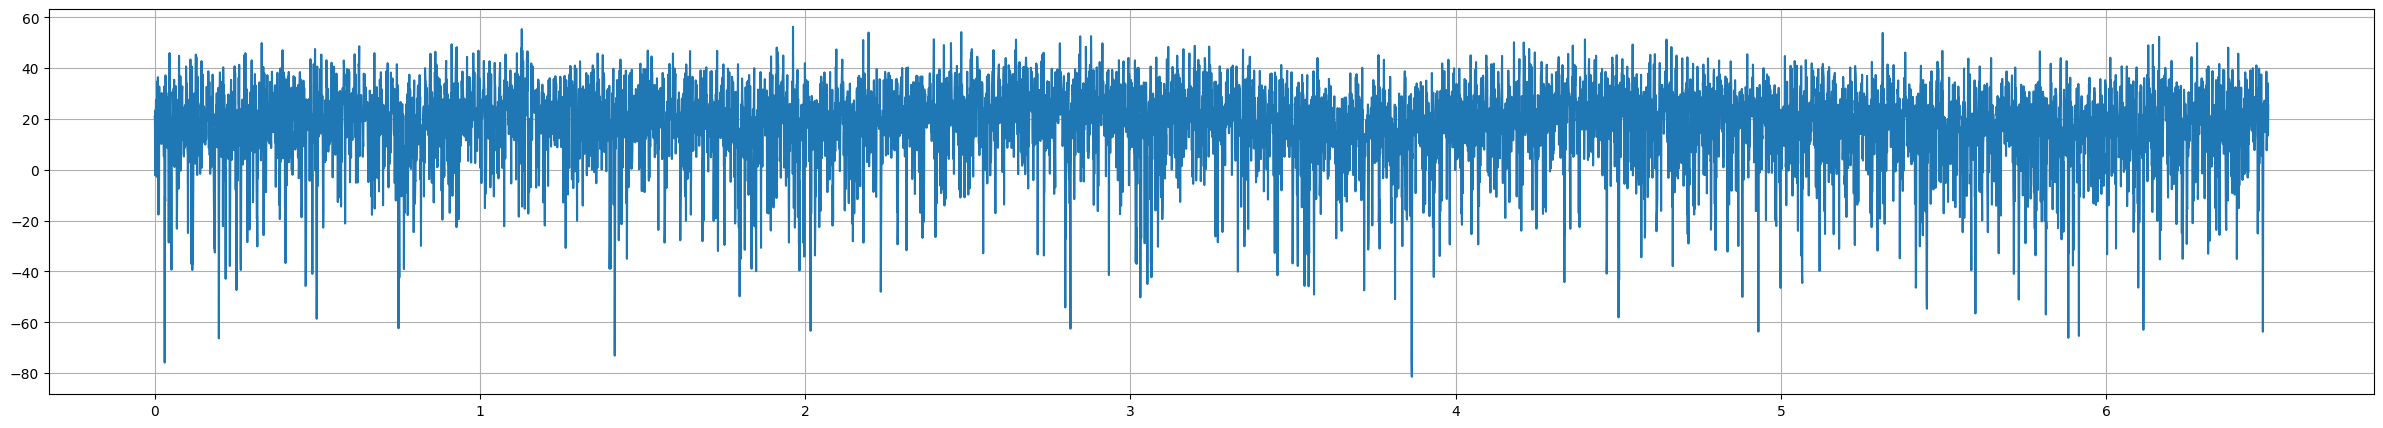

In [20]:
plt.figure(figsize=(30,5))
# plt.plot(tempos, IA_corr_A, label='IA_corr_A')
# plt.plot(tempos, IB_corr_B, label='IA_corr_B')
# plt.plot(tempos, IC_corr_C, label='IB_corr_C')
plt.plot(tempos, Ineutro, label='Ineutro')
plt.grid(True)
plt.show()

In [21]:
nnn = tempos.shape[0]
def harmonicos(nnn, Ineutro):
    fft_resultado = np.fft.fft(Ineutro)
    frequencias = np.fft.fftfreq(nnn, d=(tempos[1]-tempos[0]))
    magnitudes = 2/nnn * np.abs(fft_resultado)
    magnitudes[0] = 0.5*magnitudes[0]
    return magnitudes

magnitude_neutro = harmonicos(tempos.shape[0], Ineutro)
magnitude_A = harmonicos(tempos.shape[0], IA_corr_A)
magnitude_B = harmonicos(tempos.shape[0], IB_corr_B)
magnitude_C = harmonicos(tempos.shape[0], IC_corr_C)
frequencias = np.fft.fftfreq(nnn, d=(tempos[1]-tempos[0]))

In [22]:
magnitude_neutro.shape

(7802,)

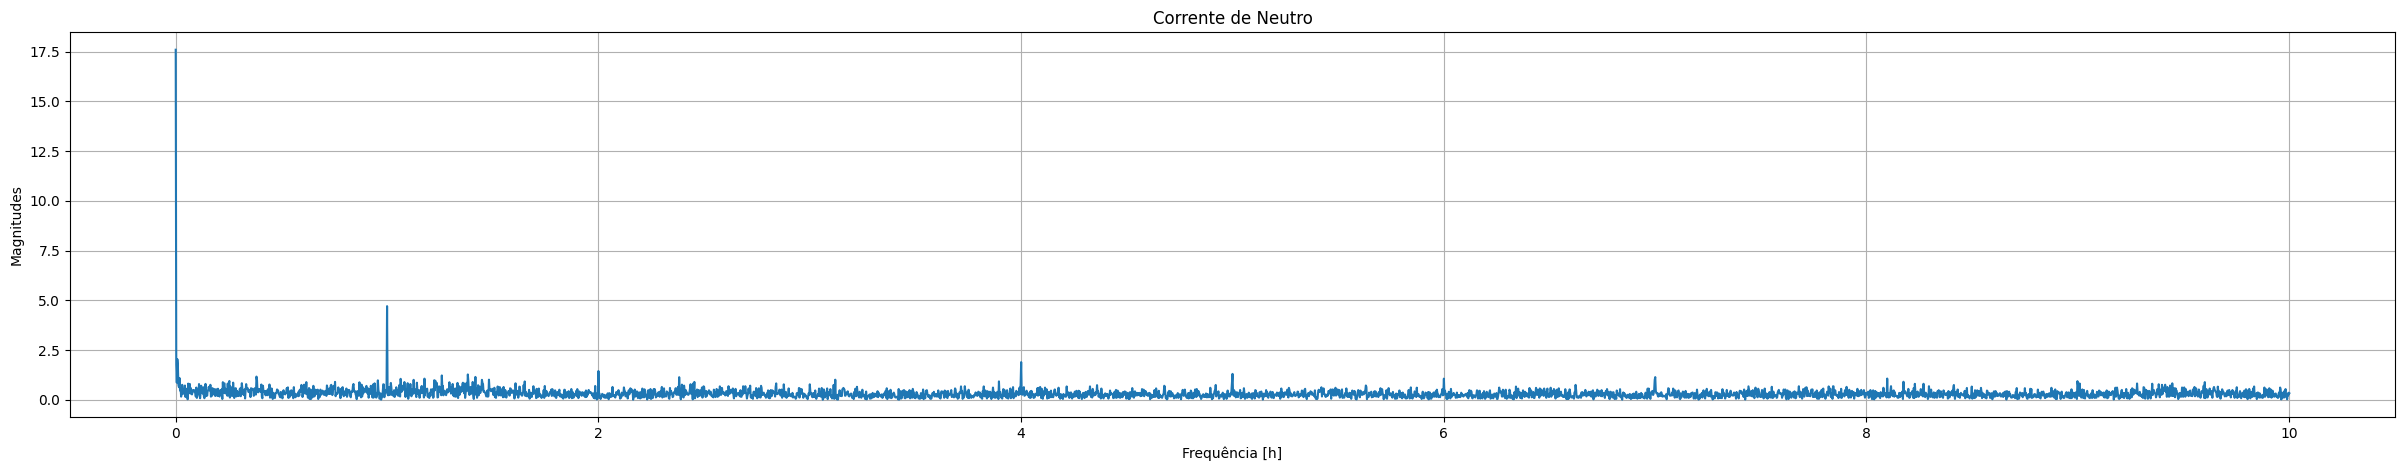

In [23]:
plt.figure(figsize=(30,5))
plt.plot(frequencias[0:int(nnn/2)]/60, magnitude_neutro[0:int(nnn/2)])
plt.title('Corrente de Neutro')
plt.xlabel('Frequência [h]')
plt.ylabel('Magnitudes')
plt.grid(True)
plt.show()

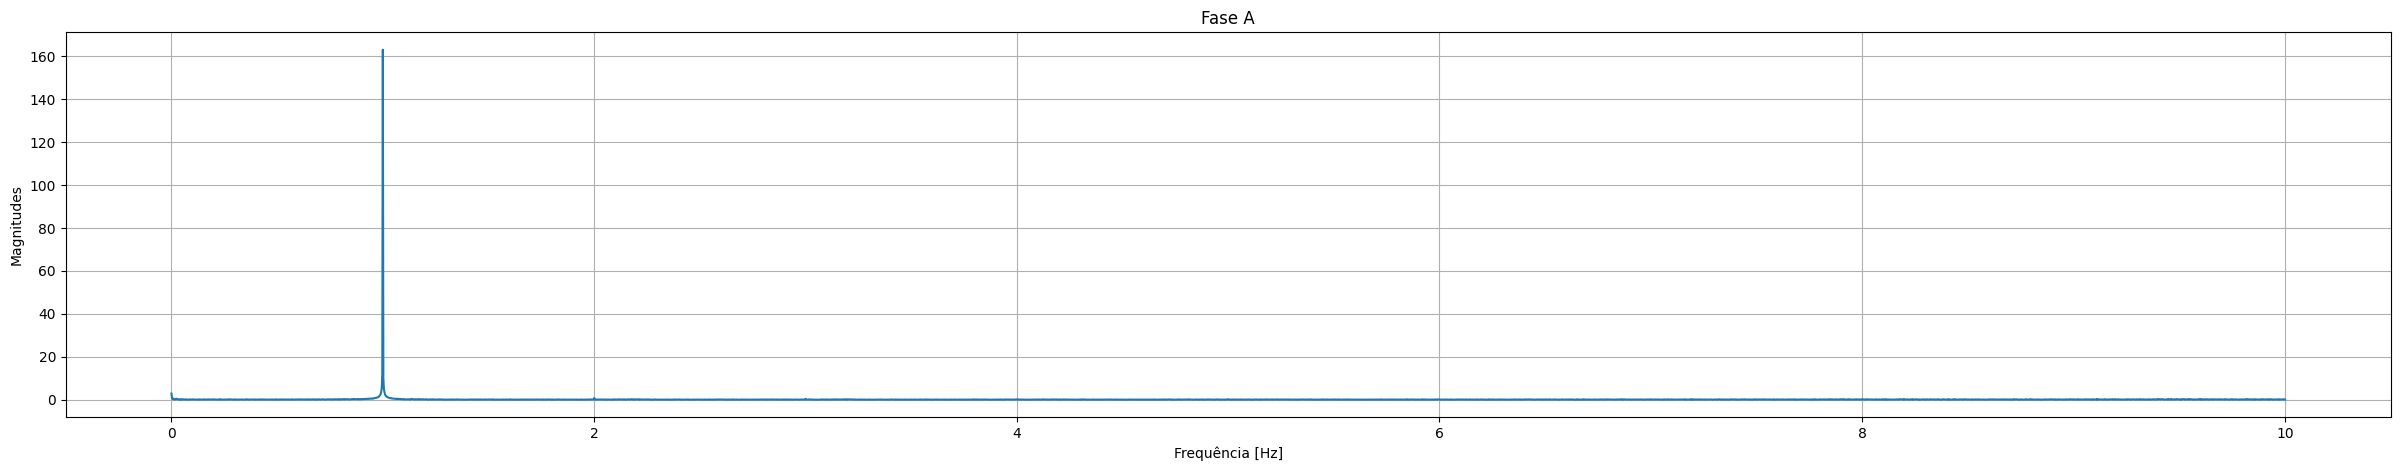

In [24]:
plt.figure(figsize=(30,5))
plt.plot(frequencias[0:int(nnn/2)]/60, magnitude_A[0:int(nnn/2)])
plt.title('Fase A')
plt.xlabel('Frequência [Hz]')
plt.ylabel('Magnitudes')
plt.grid(True)
plt.show()

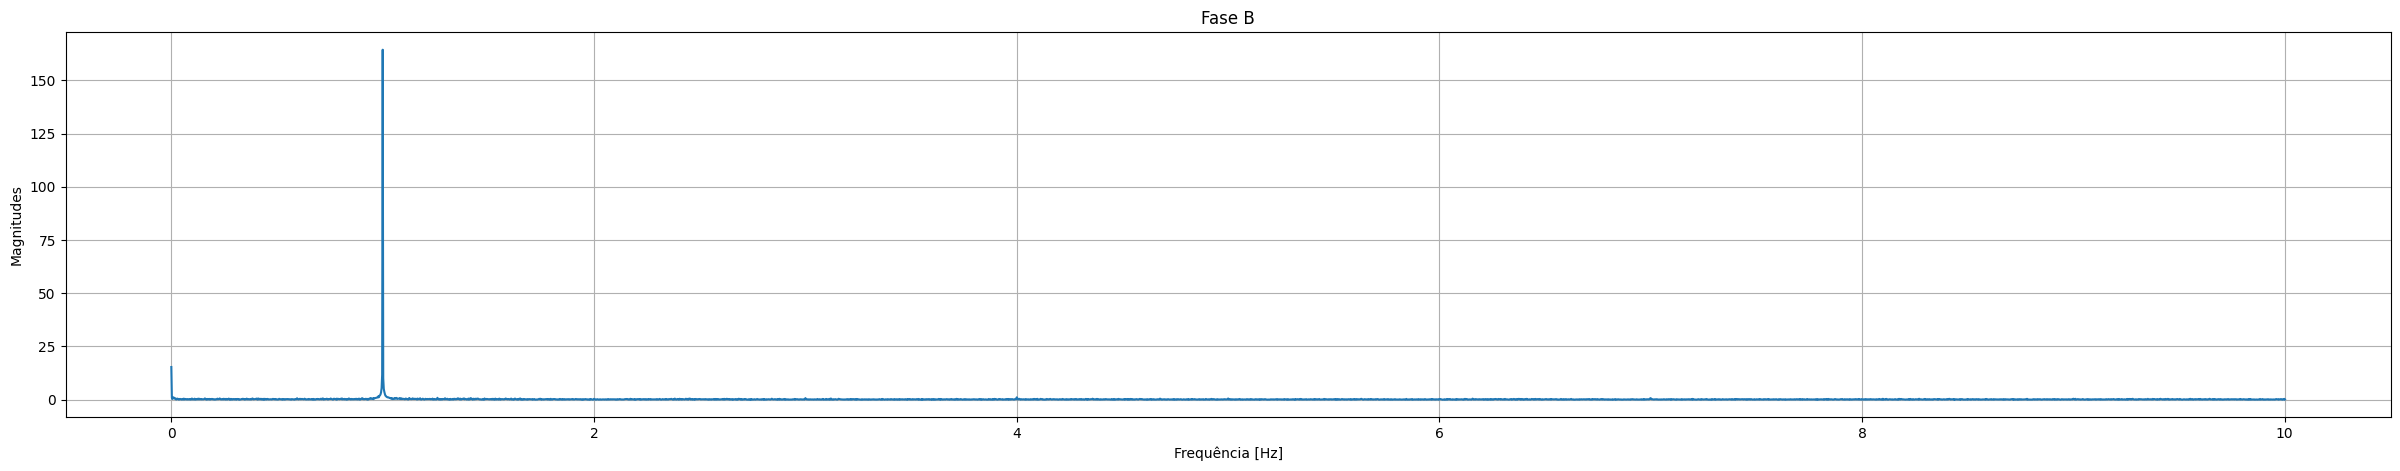

In [25]:
plt.figure(figsize=(30,5))
plt.plot(frequencias[0:int(nnn/2)]/60, magnitude_B[0:int(nnn/2)])
plt.title('Fase B')
plt.xlabel('Frequência [Hz]')
plt.ylabel('Magnitudes')
plt.grid(True)
plt.show()

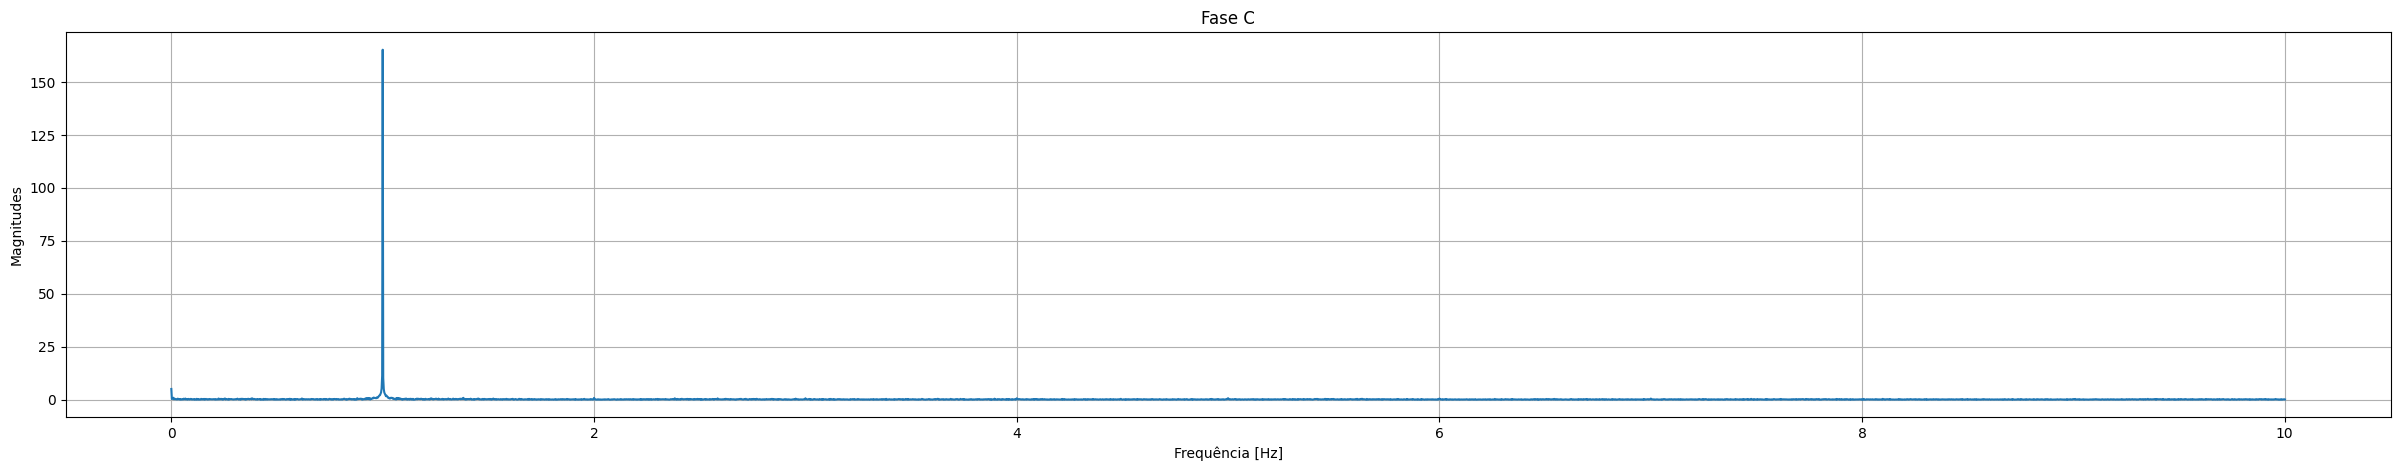

In [26]:
plt.figure(figsize=(30,5))
plt.plot(frequencias[0:int(nnn/2)]/60, magnitude_C[0:int(nnn/2)])
plt.title('Fase C')
plt.xlabel('Frequência [Hz]')
plt.ylabel('Magnitudes')
plt.grid(True)
plt.show()